# GroupMemory: more qubits and independent trainable angles

This notebook reads saved measurements, independently checks their raw records,
and displays the results. It launches **no training or simulation jobs**.
Reproduction commands are in `docs/multi_response.md`.

The planned comparison has **720 attempts and 120 matched blocks**: eight
conditions, five data seeds, three repeats, and six methods. A missing or failed
attempt remains visible. These are fresh **ideal CPU simulations**, with no QPU,
finite-shot or physical CNOT-saving claim.

Every main condition has only **four training examples**. Sensor conditions have
four held-out examples drawn from **two underlying histogram-matched pairs**;
shared-parameter conditions have sixteen held-out examples. This is a controlled
runtime and memory scaling toy, not evidence of generalization or practical
quantum machine-learning advantage.


In [1]:
from pathlib import Path
from collections import Counter
import hashlib, json, math, os, re, statistics, zipfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
%matplotlib inline

root = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists())
results = Path(os.environ.get("GROUPMEMORY_RESULTS", root / "results" / "multi-parameter"))
read = lambda name: json.loads((results / name).read_text())
analysis, config, status = read("analysis.json"), read("config.json"), read("status.json")
conditions = [c["id"] for c in config["conditions"]]
condition_specs = {c["id"]: c for c in config["conditions"]}
methods = ("group_spectral", "group_grid", "qiskit_response", "qiskit_shift",
           "classical_adjoint", "classical")
same_model = tuple(m for m in methods if m != "classical")
response_methods = ("group_spectral", "group_grid", "qiskit_response")
labels = {"group_spectral": "GroupMemory spectral", "group_grid": "Matrix-free grid",
          "qiskit_response": "Qiskit diagonal response", "qiskit_shift": "Qiskit diagonal shifts",
          "classical_adjoint": "Direct classical adjoint", "classical": "Classical task model"}
summary = {(r["condition"], r["method"]): r for r in analysis["summary"]}
comparisons = {(r["condition"], r["baseline"]): r for r in analysis["comparisons"]}
strongest = {r["condition"]: r for r in read("strongest_qiskit.json")}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
def friendly(cid):
    c = condition_specs[cid]
    task = "Sensor" if c["experiment"] == "multi_sensor" else "Shared"
    v = c["config"]
    return f"{task} · n={v['n_qubits']}, p={v['n_parameters']}, r={v['occurrences']}"
display(Markdown(
    f"Campaign status: **{status['status']}**. "
    f"Successful attempts: **{analysis['successful']}/{analysis['planned']}**. "
    f"Matched correctness blocks: **{analysis['validation_passed']}/{analysis['validation_planned']}**."))


Campaign status: **COMPLETE**. Successful attempts: **720/720**. Matched correctness blocks: **120/120**.

## What is held fixed—and what grows

All circuits have **eight trainable RY gate occurrences** separated by fixed
noncommuting RX/RZ/CZ-ring blocks. Independent angle count \(p\) and occurrence
count \(r\) satisfy \(pr=8\); qubit count varies from 8 to 14. A fitted classical
logistic head and twelve optimizer updates are shared by the same-model methods.
Five seeds vary the data, rather than the fixed architecture.

For \(p\) angles, each appearing \(r\) times, the exact state coefficient support
has \(S=(r+1)^p\) entries, while the tensor-product response grid has
\(M=(2r+1)^p\) points. The expectation uses the full signed frequency tensor:
\[
f(x,\boldsymbol\theta)
=\sum_{\boldsymbol m\in\{-r,\ldots,r\}^p}
c_{\boldsymbol m}(x)e^{i\boldsymbol m\cdot\boldsymbol\theta},
\qquad
\partial_j f
=\sum_{\boldsymbol m} im_jc_{\boldsymbol m}e^{i\boldsymbol m\cdot\boldsymbol\theta}.
\]
Mixed-sign frequencies such as \((1,-1)\) are retained.

| Method | What is evaluated |
|---|---|
| GroupMemory spectral | Matrix-free propagation of coefficient states, followed by exact response reuse |
| Matrix-free grid | The same grid and local-gate arithmetic, without coefficient-state sharing |
| Qiskit diagonal response | The same response support, cache lifetime and CZ/RZ aggregation, using Aer runtime binding |
| Qiskit diagonal shifts | The same CZ/RZ aggregation and batched valid single-occurrence shifts, summed per independent parameter |
| Direct classical adjoint | The identical model and all derivatives without a persistent response |
| Classical task model | Task-specific classical features and a fitted classifier |

Both Qiskit controls use cached diagonal vectors of length \(2^n\) to combine
the fixed CZ-ring/RZ operations, matching the aggregation available to the
custom kernels. Their setup and execution are timed. These operational
diagonal circuits are distinct from native-basis validation circuits.

The three response methods use the same exact input identities and two native
off-grid checks per newly learned response at absolute tolerance **1e-10**.
Unseen forward-only inputs execute directly once. The shift control avoids the
response table and may be preferable when that table grows expensive.
No spatial invariance or approximate input matching is assumed.


## Independent raw-record, source, timing and checkpoint audit

In [2]:
sha = lambda value: hashlib.sha256(value).hexdigest()
def valid_digest(value):
    return isinstance(value, str) and len(value) == 64 and all(c in "0123456789abcdef" for c in value)
verified = 0
for line in (results / "SHA256SUMS.txt").read_text().splitlines():
    digest, name = line.split("  ", 1)
    assert not Path(name).is_absolute() and ".." not in Path(name).parts
    assert sha((results / name).read_bytes()) == digest, name
    verified += 1
with zipfile.ZipFile(results / "source_snapshot.zip") as archive:
    for name, digest in config["source_hashes"].items():
        assert sha(archive.read("group_memory_qml/" + name)) == digest
raw_bytes, rows = {}, []
with zipfile.ZipFile(results / "raw_attempts.zip") as archive:
    available = set(archive.namelist())
    for name in available:
        assert not Path(name).is_absolute() and ".." not in Path(name).parts
    for i, spec in enumerate(config["plan"]):
        name = f"attempts/{i:05d}.json"
        if name in available:
            raw_bytes[i] = archive.read(name)
            rows.append(json.loads(raw_bytes[i]))
        else:
            rows.append({"spec": spec, "status": "UNATTEMPTED"})

blocks, operational = {}, {}
for spec, row in zip(config["plan"], rows, strict=True):
    assert row["spec"] == spec
    key = (spec["condition"], spec["seed"], spec["repeat"])
    assert spec["method"] not in blocks.setdefault(key, {})
    blocks[key][spec["method"]] = row
    if row["status"] != "SUCCESS":
        continue
    assert row["source_hashes"] == config["source_hashes"]
    assert (row["method"], row["seed"], row["experiment"]) == (
        spec["method"], spec["seed"], spec["experiment"])
    for field in ("process_wall_s", "application_s", "worker_before_write_s", "import_and_setup_s"):
        assert math.isfinite(row[field]) and row[field] > 0, (key, field)
    assert row["application_s"] <= row["worker_before_write_s"] <= row["process_wall_s"]
    assert row["import_and_setup_s"] + row["application_s"] <= row["worker_before_write_s"]
    assert sum(row["diagnostics"]["stages"].values()) <= row["application_s"]
    assert valid_digest(row["diagnostics"]["dataset_sha256"])
    assert np.isfinite(np.asarray(row["validation_vector"])).all()
    assert all(row["config"].get(k) == v for k, v in spec.get("config", {}).items())
    n, p, r = [row["config"][k] for k in ("n_qubits", "n_parameters", "occurrences")]
    assert (row["n_qubits"], row["n_parameters"]) == (n, p)
    if row["method"] == "classical":
        assert row["evaluations"] == row["total_cx"] == 0
        continue
    d = row["diagnostics"]["response"]
    assert [d[k] for k in ("n_qubits", "n_parameters", "occurrences")] == [n, p, r]
    assert d["layers"] == p*r
    assert d["response_degree_per_parameter"] == [r]*p
    assert d["response_shape"] == [2*r+1]*p
    assert d["response_grid_size"] == (2*r+1)**p
    assert d["response_state_support_size"] == (r+1)**p
    assert d["dense_block_bytes"] == 0 and not d["spatial_symmetry_reuse"]
    if row["method"] in response_methods:
        assert d["full_signed_frequency_tensor"] is True
        assert d["check_atol"] == 1e-10 and d["check_failures"] == 0
        assert d["max_check_error"] <= 1e-10
        assert d["check_evaluations"] == 2*d["cached_responses"]
    for counter in ("native_evaluations", "diagonal_evaluations", "total_circuit_evaluations"):
        assert isinstance(d[counter], int) and d[counter] >= 0
    assert row["evaluations"] == d["total_circuit_evaluations"] == d["native_evaluations"] + d["diagonal_evaluations"]
    assert row["total_cx"] == d["native_cx_work"]
    if row["method"] in ("qiskit_response", "qiskit_shift"):
        assert d["execution_mode"] == "qiskit_cached_diagonal_rx_runtime_binding"
        assert valid_digest(d["diagonal_sha256"])
        assert len(d["diagonal_operator_hashes"]) == 2
        assert all(valid_digest(value) for value in d["diagonal_operator_hashes"])
        assert d["diagonal_bytes"] == 2*(2**n)*16
        assert math.isfinite(d["diagonal_build_seconds"]) and d["diagonal_build_seconds"] > 0
        assert d["diagonal_evaluations"] > 0
        assert d["aer_fusion"] == {"enabled": True, "threshold": 0, "max_qubit": 5}
        identity = (spec["condition"], row["method"], "diagonal")
        assert operational.setdefault(identity, d["diagonal_sha256"]) == d["diagonal_sha256"]
        if row["method"] == "qiskit_shift":
            assert d["native_evaluations"] == d["native_cx_work"] == d["native_cx_per_circuit"] == 0
            assert d["native_sha256"] == d["diagonal_sha256"]
        else:
            assert d["native_evaluations"] == d["check_evaluations"]
            assert d["diagonal_evaluations"] >= d["response_grid_size"]*d["cached_responses"]
    else:
        assert d["diagonal_sha256"] is None and d["diagonal_operator_hashes"] is None
        assert d["diagonal_evaluations"] == d["diagonal_bytes"] == 0
    if row["method"] != "classical_adjoint":
        assert valid_digest(d["native_sha256"])
        identity = (spec["condition"], row["method"])
        assert operational.setdefault(identity, d["native_sha256"]) == d["native_sha256"]
        assert row["total_cx"] == d["native_cx_work"] == d["native_cx_per_circuit"]*d["native_evaluations"]
    training = row["diagnostics"]["parameter_training"]
    initial, final, displacement = [np.asarray(training[k], dtype=float) for k in ("initial", "final", "displacement")]
    assert initial.shape == final.shape == displacement.shape == (p,)
    assert np.allclose(final-initial, displacement, atol=1e-14, rtol=0)
    assert training["independent_parameters"] == p and training["updates"] == row["config"]["updates"]

good, worst = set(), 0.
for key, block in blocks.items():
    if any(block.get(m, {}).get("status") != "SUCCESS" for m in same_model):
        continue
    ref = block["qiskit_response"]
    same = [block[m] for m in same_model]
    for field in ("source_sha256", "architecture_sha256"):
        digests = [r["diagnostics"]["response"][field] for r in same]
        assert all(valid_digest(d) for d in digests) and len(set(digests)) == 1
    assert len({block[m]["diagnostics"]["response"]["native_sha256"] for m in response_methods}) == 1
    assert block["qiskit_response"]["diagnostics"]["response"]["diagonal_operator_hashes"] == block["qiskit_shift"]["diagnostics"]["response"]["diagonal_operator_hashes"]
    assert len({r["diagnostics"]["dataset_sha256"] for r in same}) == 1
    for row in same:
        expected, actual = np.asarray(ref["validation_vector"]), np.asarray(row["validation_vector"])
        assert actual.shape == expected.shape
        error = float(np.max(np.abs(actual-expected), initial=0))
        assert error <= 1e-10, (key, row["method"], error)
        worst = max(worst, error)
        assert row["metric_value"] == ref["metric_value"]
        assert row["diagnostics"]["predictions"] == ref["diagnostics"]["predictions"]
    if block.get("classical", {}).get("status") == "SUCCESS":
        assert block["classical"]["diagnostics"]["dataset_sha256"] == ref["diagnostics"]["dataset_sha256"]
    good.add(key)

def eligible_seeds(cid, method):
    return [seed for seed in config["seeds"] if all(
        (cid, seed, rep) in good and blocks[cid, seed, rep].get(method, {}).get("status") == "SUCCESS"
        for rep in range(config["repeats"]))]
def seed_median(cid, seed, method, field="process_wall_s"):
    return statistics.median(blocks[cid, seed, rep][method][field] for rep in range(config["repeats"]))
def qualifies(ratios):
    return bool(config["repeats"] >= 3 and len(ratios) >= 5 and min(ratios) > 1
                and statistics.median(1-1/r for r in ratios) >= .05)
for (cid, method), recorded in comparisons.items():
    seeds = sorted(set(eligible_seeds(cid, "group_spectral")) & set(eligible_seeds(cid, method)))
    ratios = [seed_median(cid, seed, method)/seed_median(cid, seed, "group_spectral") for seed in seeds]
    assert len(seeds) == recorded["matched_seeds"]
    assert abs(statistics.median(ratios)-recorded["paired_speedup"]) < 1e-12
    assert min(ratios) == recorded["minimum_seed_speedup"] and max(ratios) == recorded["maximum_seed_speedup"]
    assert qualifies(ratios) == recorded["descriptive_win"]
for (cid, method), recorded in summary.items():
    seeds = eligible_seeds(cid, method)
    assert len(seeds) == recorded["seeds"]
    measured = statistics.median(seed_median(cid, seed, method) for seed in seeds)
    assert abs(measured-recorded["process_wall_s"]) < 1e-12
    quality = statistics.mean(statistics.mean(
        blocks[cid, seed, rep][method]["metric_value"] for rep in range(config["repeats"])) for seed in seeds)
    assert abs(quality-recorded["accuracy"]) < 1e-12
for cid, recorded in strongest.items():
    seeds = [s for s in eligible_seeds(cid, "group_spectral")
             if s in eligible_seeds(cid, "qiskit_response") and s in eligible_seeds(cid, "qiskit_shift")]
    ratios = [min(seed_median(cid, s, "qiskit_response"), seed_median(cid, s, "qiskit_shift")) /
              seed_median(cid, s, "group_spectral") for s in seeds]
    assert len(seeds) == recorded["matched_seeds"]
    assert abs(statistics.median(ratios)-recorded["paired_speedup"]) < 1e-12
    assert qualifies(ratios) == recorded["descriptive_win"]

auth = read("authorization.json")
assert math.isfinite(auth["start_unix"]) and math.isfinite(config["budget_s"]) and config["budget_s"] > 0
expected_deadline = auth["start_unix"] + config["budget_s"]
if "hard_deadline_unix" in config:
    assert math.isfinite(config["hard_deadline_unix"]) and config["hard_deadline_unix"] > 0
    expected_deadline = min(expected_deadline, config["hard_deadline_unix"])
assert auth["deadline_unix"] == expected_deadline
manifest = read("checkpoints/manifest.json")
assert status["completed_attempts"] == manifest["completed_attempts"] == len(raw_bytes)
assert status["deadline_unix"] == manifest["deadline_unix"] == auth["deadline_unix"]
for slot in ("latest", "previous"):
    if manifest.get(slot) is None:
        continue
    path = results / "checkpoints" / manifest[slot]
    if slot == "latest":
        assert sha(path.read_bytes()) == manifest["latest_sha256"]
    cp = json.loads(path.read_text())
    count = cp["completed_attempts"]
    assert cp["config_sha256"] == sha((results / "config.json").read_bytes())
    assert cp["deadline_unix"] == auth["deadline_unix"]
    assert cp["last_result_sha256"] == sha(raw_bytes[count-1])
    assert cp["next_spec"] == (config["plan"][count] if count < len(config["plan"]) else None)
assert len(good) == analysis["validation_passed"]
assert sum(r["status"] == "SUCCESS" for r in rows) == analysis["successful"]
assert abs(worst-analysis["maximum_absolute_error"]) < 1e-20
worker_sum = sum(r.get("process_wall_s", 0.) for r in rows)
assert abs(worker_sum-analysis["sum_process_wall_s"]) < 1e-9
preflight = read("preflight.json")
assert preflight["returncode"] == 0
test_counts = re.findall(r"(\d+) passed", (results / "preflight.log").read_text())
test_count = int(test_counts[-1]) if test_counts else None
assert test_count is not None and test_count >= 435
revision = read("code_revision.json")
display(Markdown(
    f"Verified **{verified} packaged hashes**, **{len(raw_bytes)} attempted raw records**, "
    f"**{len(good)} matched blocks**, all reported paired ratios and checkpoint links. "
    f"Maximum complete forward/gradient/trajectory error: **{worst:.3g}**. "
    f"Correctness preflight: **{test_count} tests passed**. "
    f"Measured source revision: `{revision['commit'][:12]}`."))


Verified **37 packaged hashes**, **720 attempted raw records**, **120 matched blocks**, all reported paired ratios and checkpoint links. Maximum complete forward/gradient/trajectory error: **1.77e-14**. Correctness preflight: **448 tests passed**. Measured source revision: `f86f94e876e1`.

### Coverage is part of the result

The following table retains failed, timed-out and unattempted work. A timing
comparison only uses seeds with every required matching trial successful.


In [3]:
lines = ["| Condition | Success | Error | Timeout | Unattempted | Matched blocks |",
         "|---|---:|---:|---:|---:|---:|"]
for cid in conditions:
    counts = Counter(row["status"] for row in rows if row["spec"]["condition"] == cid)
    matched = sum(key[0] == cid for key in good)
    lines.append(f"| {friendly(cid)} | {counts['SUCCESS']} | {counts['ERROR']} | "
                 f"{counts['TIMEOUT']} | {counts['UNATTEMPTED']} | {matched} |")
display(Markdown("\n".join(lines)))


| Condition | Success | Error | Timeout | Unattempted | Matched blocks |
|---|---:|---:|---:|---:|---:|
| Sensor · n=8, p=1, r=8 | 90 | 0 | 0 | 0 | 15 |
| Sensor · n=8, p=2, r=4 | 90 | 0 | 0 | 0 | 15 |
| Sensor · n=8, p=4, r=2 | 90 | 0 | 0 | 0 | 15 |
| Sensor · n=12, p=2, r=4 | 90 | 0 | 0 | 0 | 15 |
| Sensor · n=12, p=4, r=2 | 90 | 0 | 0 | 0 | 15 |
| Sensor · n=14, p=2, r=4 | 90 | 0 | 0 | 0 | 15 |
| Shared · n=12, p=2, r=4 | 90 | 0 | 0 | 0 | 15 |
| Shared · n=12, p=4, r=2 | 90 | 0 | 0 | 0 | 15 |

## Complete training runtime and tiny-task accuracy

Times are medians of seed medians. Each worker includes startup, imports, input
preparation, compilation, response or shift construction, correctness checks,
cache bookkeeping, training, prediction, serialization and exit.
The task-specific classical model uses different features; the other five
methods compute the same circuit model and trajectory.

The 50% chance baseline is a label-balance reference. Four sensor test examples
and sixteen shared test examples do not support a generalization claim.


In [4]:
def table_value(cid, method, key="process_wall_s"):
    r = summary.get((cid, method))
    if r is None:
        return "missing"
    return f"{r[key]:.3f} s" if key == "process_wall_s" else f"{r[key]:.1%}"
lines = ["| Condition | Spectral | Grid | Qiskit response | Qiskit shifts | Adjoint | Classical task | Accuracy: same model / task |",
         "|---|---:|---:|---:|---:|---:|---:|---:|"]
for cid in conditions:
    times = [table_value(cid, method) for method in methods]
    quality = table_value(cid, "group_spectral", "accuracy") + " / " + table_value(cid, "classical", "accuracy")
    lines.append(f"| {friendly(cid)} | " + " | ".join(times) + f" | {quality} |")
display(Markdown("\n".join(lines)))


| Condition | Spectral | Grid | Qiskit response | Qiskit shifts | Adjoint | Classical task | Accuracy: same model / task |
|---|---:|---:|---:|---:|---:|---:|---:|
| Sensor · n=8, p=1, r=8 | 1.583 s | 1.497 s | 1.523 s | 1.756 s | 1.257 s | 1.222 s | 100.0% / 100.0% |
| Sensor · n=8, p=2, r=4 | 1.505 s | 1.563 s | 1.686 s | 1.706 s | 1.260 s | 1.216 s | 100.0% / 100.0% |
| Sensor · n=8, p=4, r=2 | 1.491 s | 1.984 s | 2.308 s | 1.773 s | 1.255 s | 1.208 s | 100.0% / 100.0% |
| Sensor · n=12, p=2, r=4 | 1.853 s | 3.682 s | 2.147 s | 3.005 s | 1.668 s | 1.223 s | 100.0% / 100.0% |
| Sensor · n=12, p=4, r=2 | 2.620 s | 20.010 s | 6.307 s | 3.317 s | 1.973 s | 1.405 s | 100.0% / 100.0% |
| Sensor · n=14, p=2, r=4 | 3.284 s | 13.420 s | 4.116 s | 7.780 s | 3.336 s | 1.241 s | 100.0% / 100.0% |
| Shared · n=12, p=2, r=4 | 1.925 s | 3.742 s | 2.188 s | 3.046 s | 1.713 s | 1.208 s | 90.0% / 100.0% |
| Shared · n=12, p=4, r=2 | 2.372 s | 20.083 s | 6.020 s | 3.058 s | 1.968 s | 1.540 s | 90.0% / 100.0% |

### Paired comparisons with both Qiskit controls

Ratios above one favor GroupMemory spectral. Ranges show the observed seed
medians, **not confidence intervals**. A descriptive win requires five complete
seeds, three matching repeats each, every seed median faster, and at least 5%
median paired saving. There is no universal-crossover or statistical-significance
claim.

The strongest-control readout chooses the faster Qiskit median within each seed.
This is a conservative comparison with measured implementations, not a deployed
selector that gets strategy selection for free.


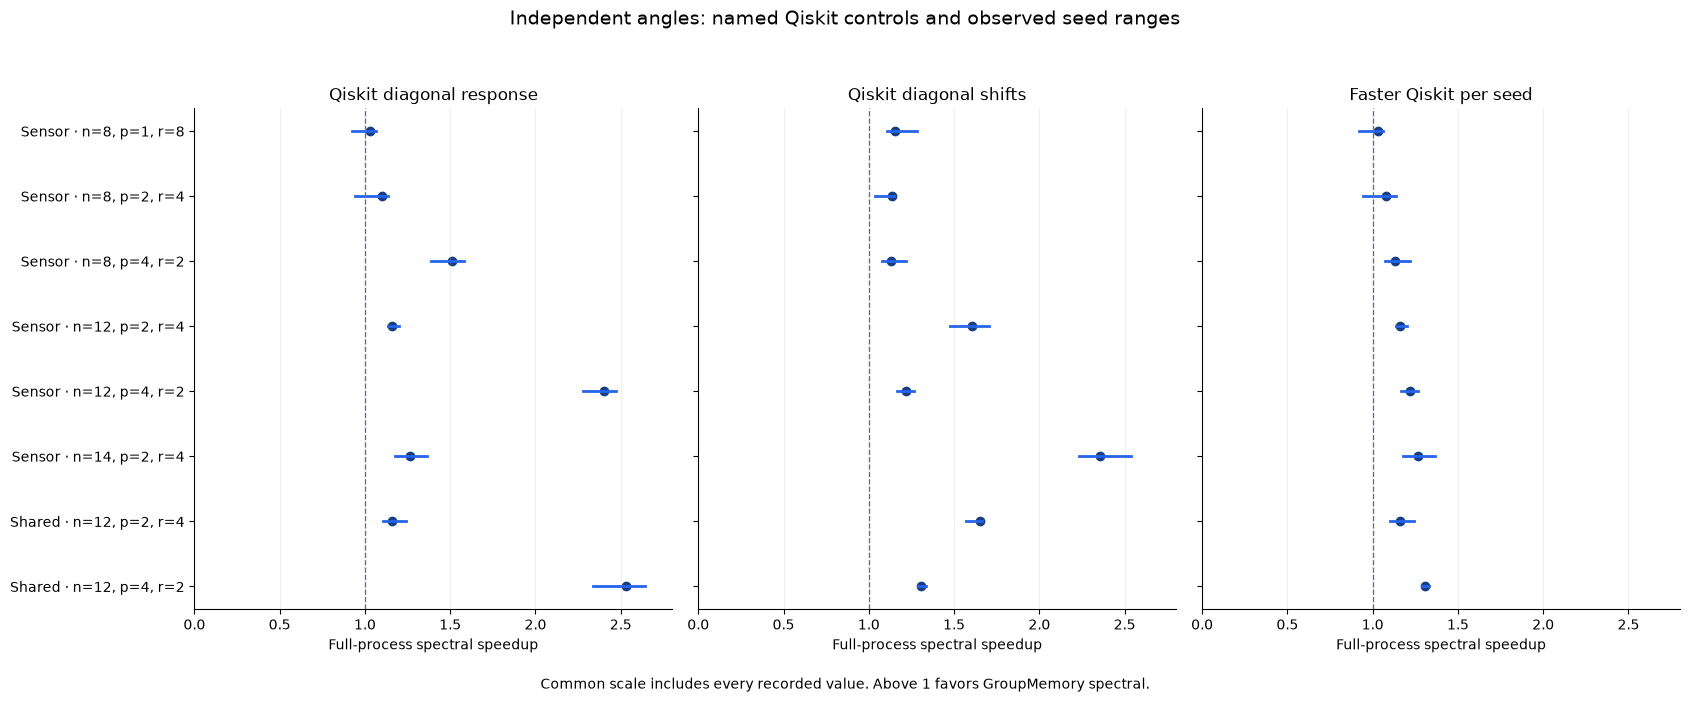

| Condition | Qiskit response | Qualifies | Qiskit shifts | Qualifies | Faster Qiskit | Qualifies |
|---|---:|---|---:|---|---:|---|
| Sensor · n=8, p=1, r=8 | 1.032× | False | 1.152× | True | 1.032× | False |
| Sensor · n=8, p=2, r=4 | 1.098× | False | 1.136× | True | 1.077× | False |
| Sensor · n=8, p=4, r=2 | 1.509× | True | 1.133× | True | 1.133× | True |
| Sensor · n=12, p=2, r=4 | 1.159× | True | 1.608× | True | 1.159× | True |
| Sensor · n=12, p=4, r=2 | 2.402× | True | 1.217× | True | 1.217× | True |
| Sensor · n=14, p=2, r=4 | 1.264× | True | 2.355× | True | 1.264× | True |
| Shared · n=12, p=2, r=4 | 1.160× | True | 1.650× | True | 1.160× | True |
| Shared · n=12, p=4, r=2 | 2.528× | True | 1.305× | True | 1.305× | True |

In [5]:
panels = ("qiskit_response", "qiskit_shift", "strongest")
panel_labels = (labels["qiskit_response"], labels["qiskit_shift"], "Faster Qiskit per seed")
def comparison_row(cid, baseline):
    return strongest.get(cid) if baseline == "strongest" else comparisons.get((cid, baseline))
available = [comparison_row(cid, b) for cid in conditions for b in panels if comparison_row(cid, b)]
xmax = max([1.2] + [r["maximum_seed_speedup"] for r in available]) * 1.06
fig, axes = plt.subplots(1, 3, figsize=(17, 7), sharey=True)
for ax, baseline, title in zip(axes, panels, panel_labels):
    for i, cid in enumerate(conditions):
        r = comparison_row(cid, baseline)
        if r is None:
            continue
        ax.plot([r["minimum_seed_speedup"], r["maximum_seed_speedup"]], [i, i],
                color="#2563eb", lw=2)
        ax.scatter(r["paired_speedup"], i, color="#173e82", s=36)
    ax.axvline(1, color="#64748b", ls="--", lw=1)
    ax.set_xlim(0, xmax)
    ax.set(title=title, xlabel="Full-process spectral speedup")
    ax.set_yticks(range(len(conditions)), [friendly(cid) for cid in conditions])
    ax.grid(axis="x", alpha=.2)
axes[0].invert_yaxis()
fig.suptitle("Independent angles: named Qiskit controls and observed seed ranges", fontsize=14)
fig.text(.5, .01, "Common scale includes every recorded value. Above 1 favors GroupMemory spectral.",
         ha="center", fontsize=10)
fig.tight_layout(rect=(0, .04, 1, .94))
fig.savefig(results / "notebook_paired_speedups.png", dpi=150)
plt.show()
lines = ["| Condition | Qiskit response | Qualifies | Qiskit shifts | Qualifies | Faster Qiskit | Qualifies |",
         "|---|---:|---|---:|---|---:|---|"]
for cid in conditions:
    values = []
    for baseline in panels:
        r = comparison_row(cid, baseline)
        values += ([f"{r['paired_speedup']:.3f}×", str(r["descriptive_win"])] if r else ["missing", "False"])
    lines.append(f"| {friendly(cid)} | " + " | ".join(values) + " |")
display(Markdown("\n".join(lines)))


### Absolute runtime across every condition

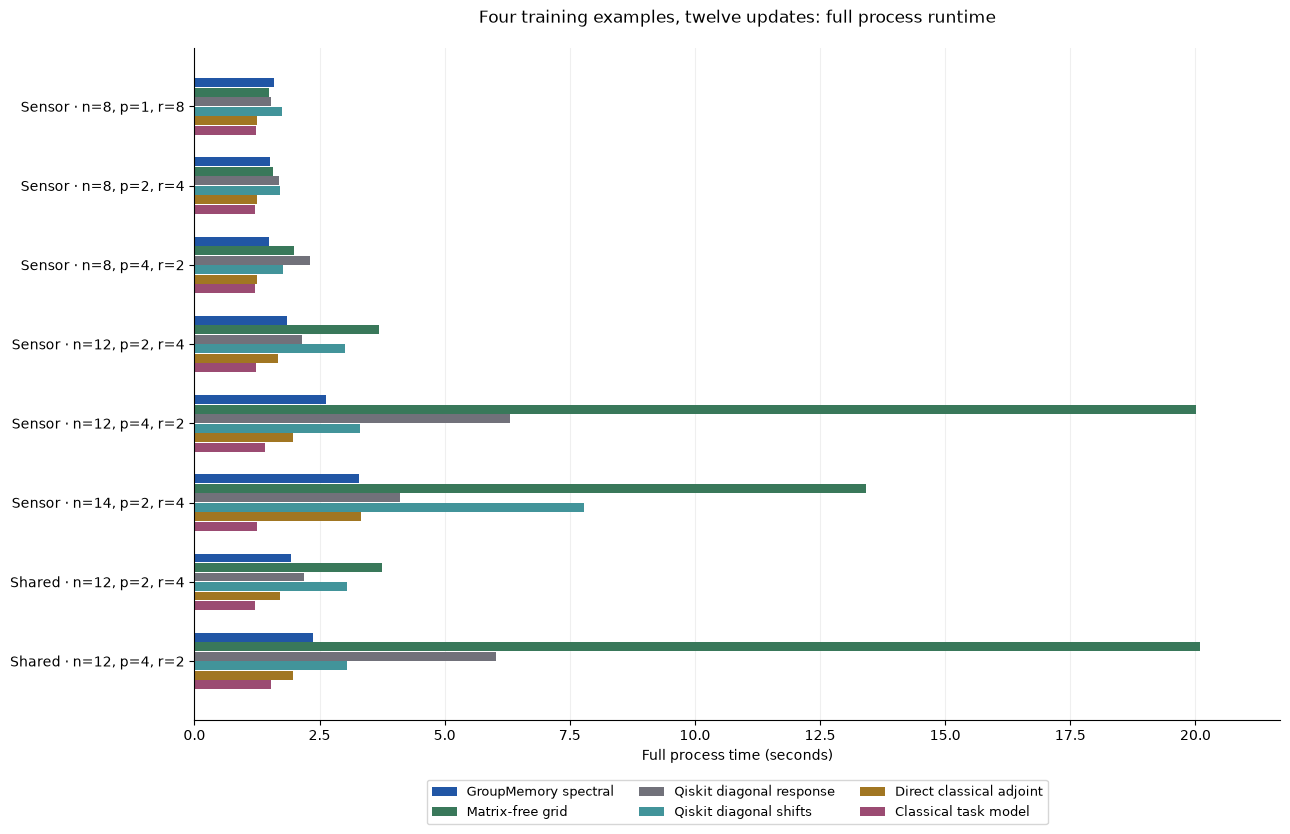

In [6]:
colors = ("#2156a5", "#39785a", "#71717a", "#42949a", "#a17622", "#9b4b72")
fig, ax = plt.subplots(figsize=(13, 9))
height = .12
for j, (method, color) in enumerate(zip(methods, colors)):
    positions, times = [], []
    for i, cid in enumerate(conditions):
        row = summary.get((cid, method))
        if row is not None:
            positions.append(i + (j-(len(methods)-1)/2)*height)
            times.append(row["process_wall_s"])
    ax.barh(positions, times, height=height*.94, color=color, label=labels[method])
maximum = max([1.] + [row["process_wall_s"] for row in summary.values()])
ax.set_xlim(0, maximum*1.08)
ax.set_yticks(range(len(conditions)), [friendly(cid) for cid in conditions])
ax.invert_yaxis()
ax.set_xlabel("Full process time (seconds)")
ax.set_title("Four training examples, twelve updates: full process runtime", pad=18)
ax.grid(axis="x", alpha=.2)
ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.08), ncol=3, fontsize=9)
fig.tight_layout(rect=(0, .06, 1, 1))
fig.savefig(results / "notebook_absolute_runtime.png", dpi=150)
plt.show()


## Did all independent angles actually participate in training?

The recorded trace includes every forward value, parameter derivative, optimizer
gradient and parameter vector at each update. This table reports observed
gradients and parameter movement, rather than assuming that declaring \(p\)
parameters means they were all updated. A displacement larger than \(10^{-10}\)
is counted as numerically nonzero. Movement alone does not establish useful
learning or generalization.


In [7]:
lines = ["| Condition | Trained angles | Moved angles across seeds | Median displacement norm | Per-angle median max absolute optimizer gradient |",
         "|---|---:|---:|---:|---|"]
for cid in conditions:
    selected = [blocks[cid, s, 0]["group_spectral"] for s in eligible_seeds(cid, "group_spectral")]
    if not selected:
        lines.append(f"| {friendly(cid)} | missing | missing | missing | missing |")
        continue
    moved, norms, gradients = [], [], []
    for row in selected:
        cfg = row["config"]
        p, updates = cfg["n_parameters"], cfg["updates"]
        count = cfg["bases"]*cfg["views"] if row["experiment"] == "multi_sensor" else cfg["n_train"]
        stride = 2*p + 1 + count + count*p
        trace = np.asarray(row["diagnostics"]["training_trajectory"])
        recorded = row["diagnostics"]["parameter_training"]
        steps = trace[:updates*stride].reshape(updates, stride)
        initial, final = np.asarray(recorded["initial"]), np.asarray(recorded["final"])
        assert np.allclose(steps[0, :p], initial, atol=1e-14, rtol=0)
        for step in range(updates-1):
            expected = steps[step, :p] - .05*np.clip(steps[step, p:2*p], -1., 1.)
            assert np.allclose(steps[step+1, :p], expected, atol=1e-12, rtol=0)
        expected_final = steps[-1, :p] - .05*np.clip(steps[-1, p:2*p], -1., 1.)
        assert np.allclose(final, expected_final, atol=1e-12, rtol=0)
        assert np.allclose(trace[updates*stride:updates*stride+p], final, atol=1e-14, rtol=0)
        moved.append(int(np.count_nonzero(np.abs(final-initial) > 1e-10)))
        norms.append(float(np.linalg.norm(final-initial)))
        gradients.append(np.max(np.abs(steps[:, p:2*p]), axis=0))
    gradient_summary = np.median(np.asarray(gradients), axis=0)
    lines.append(f"| {friendly(cid)} | {p} | {min(moved)}–{max(moved)} of {p} | "
                 f"{statistics.median(norms):.5g} | " +
                 ", ".join(f"{value:.5g}" for value in gradient_summary) + " |")
display(Markdown("\n".join(lines)))


| Condition | Trained angles | Moved angles across seeds | Median displacement norm | Per-angle median max absolute optimizer gradient |
|---|---:|---:|---:|---|
| Sensor · n=8, p=1, r=8 | 1 | 1–1 of 1 | 0.12043 | 0.21187 |
| Sensor · n=8, p=2, r=4 | 2 | 2–2 of 2 | 0.09189 | 0.15216, 0.048674 |
| Sensor · n=8, p=4, r=2 | 4 | 4–4 of 4 | 0.06653 | 0.071561, 0.009191, 0.084831, 0.011503 |
| Sensor · n=12, p=2, r=4 | 2 | 2–2 of 2 | 0.052493 | 0.030462, 0.091212 |
| Sensor · n=12, p=4, r=2 | 4 | 4–4 of 4 | 0.040544 | 0.029414, 0.060115, 0.019698, 0.0040264 |
| Sensor · n=14, p=2, r=4 | 2 | 2–2 of 2 | 0.05366 | 0.011712, 0.095881 |
| Shared · n=12, p=2, r=4 | 2 | 2–2 of 2 | 0.062164 | 0.08425, 0.072411 |
| Shared · n=12, p=4, r=2 | 4 | 4–4 of 4 | 0.040016 | 0.052857, 0.018642, 0.019643, 0.035712 |

## Response size, construction cost and memory

The parameter sweep holds eight trainable gate occurrences fixed while response
grid size rises from **17 to 81 to 625**. State support rises from **9 to 25 to 81**.
Local-gate application avoids dense \(2^n\times2^n\) block operators, but retains
exponential statevector storage. The response table also grows exponentially
with independent parameter count.

The estimated workspace covers controlled arrays and cache storage. It is
**not a hard process RSS limit**: process RSS includes Python, numerical
libraries, the simulator, and temporary storage. Bounded chunking is part of the
timed work. Native-basis validation counts and operational diagonal-circuit
counts exclude spectral, grid and adjoint arithmetic. Neither count can be read
as a physical CNOT or QPU shot saving.


In [8]:
lines = ["| Condition | S / M | Source/native depth | Native CX/circuit | Spectral calibration (s) | Qiskit diagonal response calibration (s) | Max estimated spectral workspace | Median spectral peak RSS | Spectral/grid ratio |",
         "|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
for cid in conditions:
    selected = [r for r in rows if r["spec"]["condition"] == cid and r["status"] == "SUCCESS"]
    gm = [r for r in selected if r["method"] == "group_spectral"]
    q = [r for r in selected if r["method"] == "qiskit_response"]
    if not gm or not q:
        lines.append(f"| {friendly(cid)} | missing | missing | missing | missing | missing | missing | missing | missing |")
        continue
    d = gm[0]["diagnostics"]["response"]
    calibration = lambda rr: statistics.median(r["diagnostics"]["response"]["calibration_seconds"] for r in rr)
    estimate = max(r["diagnostics"]["response"]["estimated_peak_workspace_bytes"] for r in gm)
    rss_values = [r["peak_rss_bytes"] for r in gm if r.get("peak_rss_bytes") is not None]
    rss = f"{statistics.median(rss_values)/1024**2:.1f} MiB" if rss_values else "unavailable"
    paired = comparisons.get((cid, "group_grid"))
    ratio = f"{paired['paired_speedup']:.3f}×" if paired else "missing"
    lines.append(f"| {friendly(cid)} | {d['response_state_support_size']} / {d['response_grid_size']} | "
                 f"{d['source_depth']} / {d['native_depth']} | {d['native_cx_per_circuit']} | "
                 f"{calibration(gm):.4f} | {calibration(q):.4f} | "
                 f"{estimate/1024**2:.1f} MiB | {rss} | {ratio} |")
display(Markdown("\n".join(lines)))
lines = ["| Condition | Spectral RSS | Grid RSS | Qiskit diagonal response RSS | Qiskit diagonal shifts RSS | Adjoint RSS | Classical RSS |",
         "|---|---:|---:|---:|---:|---:|---:|"]
for cid in conditions:
    memory = []
    for method in methods:
        values = [r["peak_rss_bytes"] for r in rows if r["spec"]["condition"] == cid
                  and r["spec"]["method"] == method and r["status"] == "SUCCESS"
                  and r.get("peak_rss_bytes") is not None]
        memory.append(f"{statistics.median(values)/1024**2:.1f} MiB" if values else "unavailable")
    lines.append(f"| {friendly(cid)} | " + " | ".join(memory) + " |")
display(Markdown("\n".join(lines)))
lines = ["| Condition | Spectral native checks | Qiskit response native checks | Qiskit response diagonal evaluations | Qiskit shift diagonal evaluations | Cached diagonal storage |",
         "|---|---:|---:|---:|---:|---:|"]
for cid in conditions:
    bymethod = {m: [r["diagnostics"]["response"] for r in rows
                   if r["spec"]["condition"] == cid and r["method"] == m and r["status"] == "SUCCESS"]
                for m in ("group_spectral", "qiskit_response", "qiskit_shift")}
    def count(method, field):
        return f"{statistics.median(d[field] for d in bymethod[method]):g}" if bymethod[method] else "missing"
    diagonal = bymethod["qiskit_response"]
    storage = f"{max(d['diagonal_bytes'] for d in diagonal)/1024:.0f} KiB" if diagonal else "missing"
    lines.append(f"| {friendly(cid)} | {count('group_spectral', 'native_evaluations')} | "
                 f"{count('qiskit_response', 'native_evaluations')} | "
                 f"{count('qiskit_response', 'diagonal_evaluations')} | "
                 f"{count('qiskit_shift', 'diagonal_evaluations')} | {storage} |")
display(Markdown("\n".join(lines)))


| Condition | S / M | Source/native depth | Native CX/circuit | Spectral calibration (s) | Qiskit diagonal response calibration (s) | Max estimated spectral workspace | Median spectral peak RSS | Spectral/grid ratio |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Sensor · n=8, p=1, r=8 | 9 / 17 | 52 / 156 | 64 | 0.0174 | 0.0350 | 0.9 MiB | 219.5 MiB | 1.000× |
| Sensor · n=8, p=2, r=4 | 25 / 81 | 52 / 156 | 64 | 0.0210 | 0.1108 | 2.5 MiB | 219.8 MiB | 1.018× |
| Sensor · n=8, p=4, r=2 | 81 / 625 | 52 / 156 | 64 | 0.0305 | 0.7458 | 9.7 MiB | 224.1 MiB | 1.301× |
| Sensor · n=12, p=2, r=4 | 25 / 81 | 68 / 217 | 96 | 0.2894 | 0.6011 | 38.2 MiB | 286.8 MiB | 1.987× |
| Sensor · n=12, p=4, r=2 | 81 / 625 | 68 / 217 | 96 | 0.7453 | 4.3859 | 124.1 MiB | 401.7 MiB | 7.676× |
| Sensor · n=14, p=2, r=4 | 25 / 81 | 76 / 249 | 112 | 1.4858 | 2.3232 | 152.4 MiB | 480.2 MiB | 4.064× |
| Shared · n=12, p=2, r=4 | 25 / 81 | 68 / 217 | 96 | 0.2878 | 0.5995 | 38.2 MiB | 286.7 MiB | 1.996× |
| Shared · n=12, p=4, r=2 | 81 / 625 | 68 / 217 | 96 | 0.7397 | 4.3821 | 124.1 MiB | 407.8 MiB | 8.307× |

| Condition | Spectral RSS | Grid RSS | Qiskit diagonal response RSS | Qiskit diagonal shifts RSS | Adjoint RSS | Classical RSS |
|---|---:|---:|---:|---:|---:|---:|
| Sensor · n=8, p=1, r=8 | 219.5 MiB | 219.4 MiB | 222.2 MiB | 216.8 MiB | 174.4 MiB | 173.8 MiB |
| Sensor · n=8, p=2, r=4 | 219.8 MiB | 222.5 MiB | 225.8 MiB | 216.6 MiB | 174.4 MiB | 173.7 MiB |
| Sensor · n=8, p=4, r=2 | 224.1 MiB | 263.4 MiB | 226.1 MiB | 216.8 MiB | 174.4 MiB | 173.8 MiB |
| Sensor · n=12, p=2, r=4 | 286.8 MiB | 296.6 MiB | 231.7 MiB | 221.4 MiB | 177.9 MiB | 173.8 MiB |
| Sensor · n=12, p=4, r=2 | 401.7 MiB | 366.9 MiB | 227.9 MiB | 218.5 MiB | 177.9 MiB | 173.9 MiB |
| Sensor · n=14, p=2, r=4 | 480.2 MiB | 375.0 MiB | 242.5 MiB | 232.9 MiB | 190.4 MiB | 173.9 MiB |
| Shared · n=12, p=2, r=4 | 286.7 MiB | 306.2 MiB | 231.8 MiB | 218.4 MiB | 179.6 MiB | 173.7 MiB |
| Shared · n=12, p=4, r=2 | 407.8 MiB | 366.2 MiB | 228.0 MiB | 218.5 MiB | 179.8 MiB | 173.8 MiB |

| Condition | Spectral native checks | Qiskit response native checks | Qiskit response diagonal evaluations | Qiskit shift diagonal evaluations | Cached diagonal storage |
|---|---:|---:|---:|---:|---:|
| Sensor · n=8, p=1, r=8 | 8 | 8 | 72 | 824 | 8 KiB |
| Sensor · n=8, p=2, r=4 | 8 | 8 | 328 | 824 | 8 KiB |
| Sensor · n=8, p=4, r=2 | 8 | 8 | 2504 | 824 | 8 KiB |
| Sensor · n=12, p=2, r=4 | 8 | 8 | 328 | 824 | 128 KiB |
| Sensor · n=12, p=4, r=2 | 8 | 8 | 2504 | 824 | 128 KiB |
| Sensor · n=14, p=2, r=4 | 8 | 8 | 328 | 824 | 512 KiB |
| Shared · n=12, p=2, r=4 | 8 | 8 | 340 | 836 | 128 KiB |
| Shared · n=12, p=4, r=2 | 8 | 8 | 2516 | 836 | 128 KiB |

## Formula-only scaling limits—not additional measurements

The saved resource calculation uses \(S=(r+1)^p\), \(M=(2r+1)^p\), and
\(16S2^n\) bytes for one complex128 coefficient-state tensor. This lower bound
omits temporary arrays, caches, input plans and interpreter/library memory.
It is not measured peak RSS or a runtime estimate. The larger-qubit examples
below were **not executed** and lie outside the implementation's qubit limit.


In [9]:
limits = read("resource_limits.json")
assert limits["source"]["sha256"] == config["source_hashes"]["multi_response.py"]
defaults = limits["defaults"]
chosen = [(8, 8, 1), (20, 4, 2), (24, 4, 2)]
indexed = {(r["n_qubits"], r["independent_parameters"], r["occurrences_per_parameter"]): r
           for r in limits["examples"]}
lines = ["| Formula-only example | State coefficients S | Grid points M | Bare coefficient tensor per input | Boundary |",
         "|---|---:|---:|---:|---|"]
for n, p, r in chosen:
    example = indexed[n, p, r]
    assert example["evidence_status"] == "ARITHMETIC_ONLY_NOT_A_BENCHMARK_RESULT"
    S, M = (r+1)**p, (2*r+1)**p
    bare = 16*S*(2**n)
    assert example["state_coefficient_vectors"] == S
    assert example["full_signed_response_grid_points"] == M
    assert example["one_input_state_coefficients_lower_bound_bytes"] == bare
    storage = f"{bare/1024**3:.8g} GiB" if bare >= 1024**3 else f"{bare/1024**2:.6g} MiB"
    boundary = (f"M exceeds default grid guard {defaults['max_grid_points']:,}" if M > defaults["max_grid_points"]
                else f"Beyond implemented {defaults['n_range'][1]}-qubit cap; not executed")
    lines.append(f"| n={n}, p={p}, r={r} | {S:,} | {M:,} | at least {storage} | {boundary} |")
display(Markdown("\n".join(lines)))
display(Markdown(
    f"The implementation permits at most **{defaults['n_range'][1]} qubits**. "
    f"With p=8 and r=1, **6,561** exact grid points exceed the default **{defaults['max_grid_points']:,}** response guard. "
    "That guard applies to response construction; it does not prevent direct adjoint or occurrence-shift evaluation of an eight-parameter circuit. "
    "These are classical simulator resource formulas, not physical-QPU qubit requirements or quantum advantage evidence."))


| Formula-only example | State coefficients S | Grid points M | Bare coefficient tensor per input | Boundary |
|---|---:|---:|---:|---|
| n=8, p=8, r=1 | 256 | 6,561 | at least 1 MiB | M exceeds default grid guard 4,096 |
| n=20, p=4, r=2 | 81 | 625 | at least 1.265625 GiB | Beyond implemented 16-qubit cap; not executed |
| n=24, p=4, r=2 | 81 | 625 | at least 20.25 GiB | Beyond implemented 16-qubit cap; not executed |

The implementation permits at most **16 qubits**. With p=8 and r=1, **6,561** exact grid points exceed the default **4,096** response guard. That guard applies to response construction; it does not prevent direct adjoint or occurrence-shift evaluation of an eight-parameter circuit. These are classical simulator resource formulas, not physical-QPU qubit requirements or quantum advantage evidence.

## Full timing ledger and evidence limits

Primary comparisons include all per-method costs. Parent orchestration,
correctness preflight, bounded cost pilot, checkpoint/resume quick run and
reporting have separate receipts. They are not silently omitted or arbitrarily
assigned to one method. Installation and implementation work are excluded.
The main deadline was fixed before launch; it was not extended to complete
favorable cases.

Any improvement is a result for these small-data CPU implementations. The
batched-grid ablation tests whether spectral sharing adds value beyond batching.
The Qiskit diagonal-shift control tests whether building a response is the
right strategy at all. The direct adjoint and classical task model expose
efficient classical alternatives. Earlier dense-block timings and pilot
measurements are not pooled with this campaign. A native-only preliminary run
was stopped to add the missing fixed-block aggregation control; its timing
records are excluded from final comparisons. Its elapsed time remains in the
cost ledger and inside the original unchanged main deadline.


In [10]:
ledger = read("wall_accounting.json")
external = read("main_external_wall.json")
assert external["seconds"] >= worker_sum
display(Markdown(
    f"Main parent process: **{external['seconds']/60:.2f} minutes**; "
    f"all attempted worker clocks: **{worker_sum/60:.2f} minutes**. "
    f"Parent remainder: **{external['seconds']-worker_sum:.3f} seconds**."))
print(json.dumps(ledger, indent=2))
winning = [friendly(cid) for cid in conditions if strongest.get(cid, {}).get("descriptive_win")]
grid_wins = [cid for cid in conditions if comparisons.get((cid, "group_grid"), {}).get("descriptive_win")]
adjoint_faster = [cid for cid in conditions if (cid, "classical_adjoint") in summary
                  and (cid, "group_spectral") in summary and
                  summary[cid, "classical_adjoint"]["process_wall_s"] < summary[cid, "group_spectral"]["process_wall_s"]]
text = (f"Qualifying wins against the faster Qiskit control: **{len(winning)}/{len(conditions)}**. "
        + ("Conditions: " + "; ".join(winning) + ". " if winning else "")
        + f"Qualifying spectral wins over the grid ablation: **{len(grid_wins)}/{len(conditions)}**. "
        + f"The identical-model adjoint has a lower median time in **{len(adjoint_faster)}/{len(conditions)}** conditions. "
        + "These are descriptive CPU timing results. Parameter movement and tiny held-out accuracy do not establish generalization, QPU advantage or LLM feasibility.")
display(Markdown(text))


Main parent process: **40.46 minutes**; all attempted worker clocks: **40.43 minutes**. Parent remainder: **2.028 seconds**.

{
  "main_external_wall_s": 2427.5540781250456,
  "main_worker_wall_sum_s": 2425.5264690296026,
  "main_parent_overhead_s": 2.02760909544304,
  "main_loop_wall_s": 2427.4305736250244,
  "preflight_external_s": 28.20230862504104,
  "main_report_s": 0.7435947080375627,
  "scope": "All per-method fresh process overhead included. Parent orchestration, preflight, resume smoke, cost pilot and readout reported separately. Installation and development excluded.",
  "quick_external_wall_s": 20.311389124952257,
  "quick_report_s": 0.5162649580161087,
  "cost_pilot_external_wall_s": 71.60097400000086,
  "cost_pilot_report_s": 0.5009873330127448,
  "initial_report_before_label_correction_s": 0.7532641250290908,
  "initial_packaging_s": 0.8175374580314383,
  "original_start_unix": 1792506131.885418,
  "original_deadline_unix": 1792510331.885418,
  "original_allowance_s": 4200.0,
  "excluded_preliminary_run_s": 494.6930310726166,
  "excluded_preliminary_completed_attempts": 101,
  "final_campaign_st

Qualifying wins against the faster Qiskit control: **6/8**. Conditions: Sensor · n=8, p=4, r=2; Sensor · n=12, p=2, r=4; Sensor · n=12, p=4, r=2; Sensor · n=14, p=2, r=4; Shared · n=12, p=2, r=4; Shared · n=12, p=4, r=2. Qualifying spectral wins over the grid ablation: **6/8**. The identical-model adjoint has a lower median time in **7/8** conditions. These are descriptive CPU timing results. Parameter movement and tiny held-out accuracy do not establish generalization, QPU advantage or LLM feasibility.